In [1]:
# =====================================================================
import os, sys, re, gc, math, glob, time, random, warnings, subprocess, importlib, contextlib

os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")


def _ensure(pip_name, import_name):
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=False)


for _p, _i in [("transformers", "transformers"), ("scikit-learn", "sklearn"),
               ("pandas", "pandas"), ("scipy", "scipy")]:
    _ensure(_p, _i)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, accuracy_score, precision_score,
                             recall_score, log_loss)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"

# =====================================================================
# CONFIGURATION  (edit here)
# =====================================================================
CFG = dict(
    dataset="multi-lang",            # "ghadhab" or "multi-lang"
    data_path=None,               # explicit CSV path (optional)
    strict_dropna=False,          # True = also drop rows with missing message/diff (old behaviour)
    out_dir=None,                 # where to save the CSV (default: /kaggle/working or cwd)

    # ---- encoders (any HF checkpoint that AutoModel can load) ----
    msg_encoders=["sentence-transformers/all-mpnet-base-v2",
                  "sentence-transformers/paraphrase-mpnet-base-v2"],
    code_encoder="microsoft/unixcoder-base",
    ft_backbones=["microsoft/unixcoder-base",
                  "sentence-transformers/all-mpnet-base-v2"],   # fine-tuned in FULL mode
    con_backbone="sentence-transformers/paraphrase-mpnet-base-v2",  # contrastive FT in FEW-SHOT mode
    msg_max_len=96, diff_max_len=320, joint_max_len=384, enc_bs=32, diff_chars=1200,

    # ---- full supervision ----
    full_ft=True, ft_seeds=[42, 43, 44], ft_epochs=8, ft_lr=3e-5, ft_bs=16, ft_max_len=384,
    lr_grid=[1, 4, 16, 64],

    # ---- few-shot ----
    shots=[1, 5, 10, 15, 20], fs_seeds=[42, 43, 44, 45, 46],
    fs_contrastive=True, fs_con_lr=3e-5, fs_con_bs=16, fs_con_max_len=320, fs_con_weight=2.0,
    tau=25.0,            # softmax temperature of the prototype head
    fs_C=10.0,           # LR strength for tiny support sets (old code: 1.0 = badly under-fit)
    anchor_mass=1.5,     # total weight of definitional anchors per class at K=1 (decays ~1/sqrt(K))
    lex_weight=0.6, lex_beta=1.2,   # keyword-lexicon prior
    self_train=False,    # OPTIONAL semi-supervised step on the *unlabelled* train pool
    self_train_per_class=10, self_train_w=0.5,

    # ---- optional: put the numbers you must beat, e.g. {"Full": 80.06, "5-Shot": 70.0}
    sota_f1={},
)

CLASSES = ["Corrective", "Adaptive", "Perfective"]
LABEL_TO_ID = {c: i for i, c in enumerate(CLASSES)}
NC = 3

LABEL_MAP = {
    'c': 'Corrective', 'corrective': 'Corrective', '1': 'Corrective',
    'a': 'Adaptive', 'adaptive': 'Adaptive', '0': 'Adaptive',
    'p': 'Perfective', 'perfective': 'Perfective', '2': 'Perfective',
}

# Swanson-style definitional anchors (unified format, as in the original code)
CLASS_DEFINITIONAL_ANCHORS = {
    'Corrective': "[STRUCTURAL INTENT]: [COND_OR_ERROR_HANDLING], [BUG_CORRECTION_SEMANTICS]\n[COMMIT MESSAGE]: Fix runtime bug, resolve null pointer exception, repair defect, and handle errors.\n[DISTILLED CODE DIFF]:\n- if (target == null)\n+ if (target != null && target.isValid())\n+ catch (Exception e) { log.error(e); }",
    'Adaptive': "[STRUCTURAL INTENT]: [NEW_DECLARATION_OR_API], [NEW_FILE_CREATED]\n[COMMIT MESSAGE]: Add new feature, implement public API interface, export new functionality, and extend module.\n[DISTILLED CODE DIFF]:\n+ public interface NewServiceAPI {\n+     void registerExtension();\n+ }",
    'Perfective': "[STRUCTURAL INTENT]: [DOC_OR_CONFIG_MODIFIED], [LOCAL_REFACTORING_OR_RENAME]\n[COMMIT MESSAGE]: Refactor internal code structure, clean up dead code, optimize design, and update documentation.\n[DISTILLED CODE DIFF]:\n- int old_counter = 0;\n+ int cleanIndex = 0;\n// Optimize internal memory layout",
}

# Generic pseudo commit messages (definitions only - no dataset text)
PSEUDO_MESSAGES = {
    'Corrective': ["fix bug in null pointer handling", "fixed crash when the file is missing",
                   "resolve exception thrown on invalid input", "correct wrong result in calculation",
                   "fix failing test case", "patch memory leak", "handle error case that caused failure",
                   "repair broken behaviour after regression"],
    'Adaptive': ["add new feature to support additional format", "implement new API endpoint",
                 "introduce support for a new platform", "create new class for the extension mechanism",
                 "add option to configure new behaviour", "upgrade dependency to a newer version",
                 "extend module with new functionality", "port code to the new library version"],
    'Perfective': ["refactor code to improve readability", "clean up unused code and imports",
                   "rename variables for clarity", "update documentation and comments",
                   "optimize performance of the internal loop", "simplify method structure",
                   "reformat code style", "reorganize package structure"],
}

LEXICON = {
    'Corrective': [r"\bfix(es|ed|ing)?\b", r"\bbugs?(fix)?\b", r"\b(error|errors|fail|fails|failed|failure|crash\w*|exception|npe)\b",
                   r"\b(issue|issues|defect|problem|incorrect\w*|wrong|broken|regression|leak\w*|resolv\w+|repair\w*|patch\w*|hotfix|workaround|mistake|revert\w*)\b",
                   r"\bnull ?pointer\b"],
    'Adaptive': [r"\badd(s|ed|ing)?\b", r"\bnew\b", r"\bimplement\w*", r"\bsupport(s|ed|ing)?\b", r"\bintroduc\w+",
                 r"\bcreate[sd]?\b", r"\benable[sd]?\b", r"\bextend\w*", r"\ballow(s|ed)?\b", r"\bupgrad\w+",
                 r"\bmigrat\w+", r"\bport(ed|ing)?\b", r"\bintegrat\w+", r"\bfeature\w*"],
    'Perfective': [r"\brefactor\w*", r"\bclean(s|ed|ing)?( ?up)?\b", r"\brenam\w+", r"\bmov(e|ed|ing)\b", r"\bsimplif\w+",
                   r"\boptimi[sz]\w+", r"\bimprov\w+", r"\bperformance\b", r"\bdocs?\b", r"\bdocumentation\b", r"\bjavadoc\b",
                   r"\bcomments?\b", r"\bformat\w*", r"\bstyle\b", r"\bunused\b", r"\bdeprecat\w+", r"\breorgani[sz]\w+",
                   r"\brestructur\w+", r"\breadme\b", r"\bwhitespace\b", r"\blicen[sc]e\b", r"\btypos?\b", r"\bremov(e|ed|ing)\b",
                   r"\bcosmetic\b", r"\btidy\b", r"\bredundan\w+"],
}
LEX_RE = {c: [re.compile(p, re.I) for p in ps] for c, ps in LEXICON.items()}


# =====================================================================
# GENERIC HELPERS
# =====================================================================
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def free():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _s(x):
    if x is None or (not isinstance(x, str) and pd.isna(x)):
        return ""
    return str(x)


def l2n(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-8)


def softmax_np(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def metrics(y, p):
    return {"Accuracy": accuracy_score(y, p),
            "Precision": precision_score(y, p, average="macro", zero_division=0),
            "Recall": recall_score(y, p, average="macro", zero_division=0),
            "F1-score": f1_score(y, p, average="macro", zero_division=0)}


def amp():
    return torch.autocast(device_type="cuda", dtype=torch.float16) if USE_AMP else contextlib.nullcontext()


def make_scaler():
    if not USE_AMP:
        return None
    try:
        return torch.amp.GradScaler("cuda")
    except Exception:
        return torch.cuda.amp.GradScaler()


def backward_step(loss, opt, sch, scaler, params, clip=1.0):
    if scaler is not None:
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, clip)
        scaler.step(opt)
        scaler.update()
    else:
        loss.backward()
        torch.nn.utils.clip_grad_norm_(params, clip)
        opt.step()
    sch.step()
    opt.zero_grad(set_to_none=True)


def mean_pool(h, mask):
    m = mask.unsqueeze(-1).to(h.dtype)
    return (h * m).sum(1) / m.sum(1).clamp(min=1e-6)


def embed_batch(model, tok, texts, max_len):
    enc = tok(texts, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
    with amp():
        h = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).last_hidden_state
    return mean_pool(h.float(), enc["attention_mask"])


@torch.inference_mode()
def encode_texts(model, tok, texts, max_len, bs):
    model.eval()
    texts = list(texts)
    if not texts:
        return np.zeros((0, model.config.hidden_size), dtype=np.float32)
    order = np.argsort([len(t) for t in texts])
    chunks = []
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        chunks.append(embed_batch(model, tok, [texts[j] for j in idx], max_len).cpu().numpy())
    E = np.concatenate(chunks)
    out = np.zeros_like(E)
    out[order] = E
    return out


# =====================================================================
# 1. TEXT / STRUCTURE EXTRACTION
# =====================================================================
def clean_msg(m):
    m = _s(m).replace("\r", " ")
    return re.sub(r"\s+", " ", m).strip()[:400]


def _diff_parts(d):
    add = re.findall(r"^\+(?!\+)(.*)$", d, re.M)
    rem = re.findall(r"^-(?!-)(.*)$", d, re.M)
    files = re.findall(r"^\+\+\+\s+(?:b/)?(.*)$", d, re.M)
    files += re.findall(r"^diff --git a/(\S+)", d, re.M)
    files = [f.strip() for f in dict.fromkeys(files) if f.strip() and f.strip() != "/dev/null"]
    return add, rem, files


def _tags(msg, d, add, rem, files):
    added_text, removed_text = " ".join(add), " ".join(rem)
    tags = []
    if re.search(r"\b(if|catch|try|except|throw|throws|assert|null|nil|None)\b", added_text):
        tags.append("[COND_OR_ERROR_HANDLING]")
    if re.search(r"\b(fix|bug|issue|crash|error|fail|leak)\b", msg + " " + added_text + " " + removed_text, re.I):
        tags.append("[BUG_CORRECTION_SEMANTICS]")
    if re.search(r"\b(class|def|function|interface|public|export|import|include|new)\b", added_text):
        tags.append("[NEW_DECLARATION_OR_API]")
    if "new file mode" in d:
        tags.append("[NEW_FILE_CREATED]")
    if any(f.lower().endswith(('.md', '.txt', '.json', '.yml', '.yaml', '.xml')) for f in files):
        tags.append("[DOC_OR_CONFIG_MODIFIED]")
    if add and rem and abs(len(add) - len(rem)) <= 3:
        tags.append("[LOCAL_REFACTORING_OR_RENAME]")
    return tags


def build_parts(msg, diff):
    m = clean_msg(msg)
    d = _s(diff)
    add, rem, files = _diff_parts(d)
    tags = _tags(m, d, add, rem, files)
    exts = list(dict.fromkeys([os.path.splitext(f)[1] for f in files if os.path.splitext(f)[1]]))
    ext_str = ", ".join(exts)[:40] if exts else "none"
    intent = f"[STRUCTURAL INTENT]: {', '.join(tags) if tags else '[GENERAL_MODIFICATION]'} (exts: {ext_str})"

    lines = [l[:120] for l in d.splitlines()
             if l.startswith(("+", "-")) and not l.startswith(("+++", "---"))][:30]
    if not lines:   # diff not in +/- format: fall back to the first raw lines
        lines = [l.strip()[:120] for l in d.splitlines() if l.strip()][:30]
    dtxt = "\n".join(lines)
    if files:
        dtxt = "FILES: " + ", ".join(files[:5]) + "\n" + dtxt
    dtxt = dtxt[:CFG["diff_chars"]]

    unified = (f"{intent}\n[COMMIT MESSAGE]: {m or '[NO_MESSAGE]'}\n"
               f"[DISTILLED CODE DIFF]:\n{dtxt or '[NO_DIFF]'}")
    unified_nodiff = (f"[STRUCTURAL INTENT]: [GENERAL_MODIFICATION]\n[COMMIT MESSAGE]: {m or '[NO_MESSAGE]'}\n"
                      f"[DISTILLED CODE DIFF]:\n[NO_DIFF]")
    return dict(m=m, intent=intent, dtxt=dtxt, unified=unified, unified_nodiff=unified_nodiff)


def lex_counts(msg):
    m = clean_msg(msg)
    return np.array([min(3, sum(len(r.findall(m)) for r in LEX_RE[c])) for c in CLASSES], dtype=float)


def lex_probs_from_counts(cnt, beta):
    p = np.exp(beta * cnt)
    p[cnt.sum(axis=1) == 0] = 1.0
    return p / p.sum(axis=1, keepdims=True)


STRUCT_EXTS = ['.java', '.py', '.js', '.c', '.cpp', '.h', '.md', '.txt', '.xml', '.json',
               '.yml', '.yaml', '.gradle', '.properties', '.html', '.css']


def struct_features(msg, diff):
    m = clean_msg(msg); ml = m.lower(); d = _s(diff)
    add, rem, files = _diff_parts(d)
    exts = [os.path.splitext(f)[1].lower() for f in files]
    na, nr = len(add), len(rem)
    f = [math.log1p(na), math.log1p(nr), math.log1p(len(files)), (na - nr) / (na + nr + 1.0),
         float(na > 0 and nr == 0), float(nr > 0 and na == 0), float(na > 0 and nr > 0 and abs(na - nr) <= 3),
         float("new file mode" in d), float("deleted file mode" in d),
         float("rename from" in d or "similarity index" in d)]
    f += [float(e in exts) for e in STRUCT_EXTS]
    f.append(float(any("test" in x.lower() for x in files)))
    f.append(float(len(files) > 0 and all("test" in x.lower() for x in files)))
    nz = [l.strip() for l in add + rem if l.strip()]
    is_c = lambda l: l.startswith(("//", "/*", "*", "#", '"""', "'''", "<!--"))
    f.append(sum(is_c(l) for l in nz) / len(nz) if nz else 0.0)
    f.append(float(len(nz) > 0 and all(is_c(l) for l in nz)))
    norm = lambda L: re.sub(r"\s+", "", "".join(L))
    f.append(float(na > 0 and nr > 0 and norm(add) == norm(rem)))
    f.append(float(len(nz) > 0 and all(l.startswith(("import ", "from ", "#include", "package ")) for l in nz)))
    tags = _tags(m, d, add, rem, files)
    for t in ["[COND_OR_ERROR_HANDLING]", "[BUG_CORRECTION_SEMANTICS]", "[NEW_DECLARATION_OR_API]",
              "[NEW_FILE_CREATED]", "[DOC_OR_CONFIG_MODIFIED]", "[LOCAL_REFACTORING_OR_RENAME]"]:
        f.append(float(t in tags))
    f += [math.log1p(len(m.split())), float(bool(re.search(r"#\d+|\b[A-Z]{2,}-\d+\b", m))),
          float("merge" in ml)]
    f += list(np.log1p(lex_counts(m)))
    return f


def code_tokens(text):
    out = []
    for t in re.findall(r"[A-Za-z][A-Za-z0-9]*", text):
        out += re.sub(r"([a-z0-9])([A-Z])", r"\1 \2", t).lower().split()
    return out


def diff_token_doc(dtxt):
    a = [l[1:] for l in dtxt.splitlines() if l.startswith("+")]
    r = [l[1:] for l in dtxt.splitlines() if l.startswith("-")]
    return " ".join(["a_" + t for t in code_tokens(" ".join(a))] + ["d_" + t for t in code_tokens(" ".join(r))])


def anchors_for(kind):
    texts, labels = [], []
    if kind == "msg":
        for c in CLASSES:
            for t in PSEUDO_MESSAGES[c]:
                texts.append(t); labels.append(LABEL_TO_ID[c])
    elif kind == "diff":
        for c in CLASSES:
            texts.append(CLASS_DEFINITIONAL_ANCHORS[c].split("[DISTILLED CODE DIFF]:\n", 1)[1]); labels.append(LABEL_TO_ID[c])
    else:
        for c in CLASSES:
            texts.append(CLASS_DEFINITIONAL_ANCHORS[c]); labels.append(LABEL_TO_ID[c])
    return texts, np.array(labels)


# =====================================================================
# 2. DATA LOADING  (same 70/15/15, random_state=42 split as BooCC setup)
# =====================================================================
def normalize_label(v):
    s = _s(v).strip().lower()
    if s in LABEL_MAP:
        return LABEL_MAP[s]
    try:
        s2 = str(int(float(s)))
        if s2 in LABEL_MAP:
            return LABEL_MAP[s2]
    except Exception:
        pass
    for pref, name in (("corr", "Corrective"), ("adap", "Adaptive"), ("perf", "Perfective")):
        if s.startswith(pref):
            return name
    return None


def _pick_col(df, exact, contains, exclude=(), text_only=False):
    low = {c: str(c).lower().strip() for c in df.columns}
    ok = lambda c: c not in exclude and not (text_only and pd.api.types.is_numeric_dtype(df[c]))
    for name in exact:
        for c, l in low.items():
            if l == name and ok(c):
                return c
    for c, l in low.items():
        if ok(c) and any(sub in l for sub in contains):
            return c
    return None


def load_dataset_by_name_strict(dataset_name="ghadhab"):
    name = dataset_name.lower()
    if CFG["data_path"]:
        paths, globs = [CFG["data_path"]], []
    elif name == "ghadhab":
        paths = ["/kaggle/input/datasets/zohrehsadatsajjadi/ghadhab/Ghadhab.csv",
                 "/kaggle/input/ghadhab/Ghadhab.csv", "./Ghadhab.csv"]
        globs = ["/kaggle/input/**/Ghadhab*.csv", "/kaggle/input/**/ghadhab*.csv"]
    else:
        paths = ["/kaggle/input/datasets/zohrehsadatsajjadi/multi-lang-annotated/multi-lang-annotated.csv",
                 "/kaggle/input/multi-lang-annotated/multi-lang-annotated.csv", "./multi-lang-annotated.csv"]
        globs = ["/kaggle/input/**/multi-lang*.csv"]
    file_path = next((p for p in paths if os.path.exists(p)), None)
    if not file_path:
        for g in globs:
            hits = sorted(glob.glob(g, recursive=True))
            if hits:
                file_path = hits[0]; break
    if not file_path:
        raise FileNotFoundError(f"{dataset_name} dataset not found. Set CFG['data_path'] to the CSV.")

    try:
        raw = pd.read_csv(file_path, low_memory=False, on_bad_lines="skip")
    except UnicodeDecodeError:
        raw = pd.read_csv(file_path, low_memory=False, on_bad_lines="skip", encoding="latin-1")

    msg_col = _pick_col(raw, ["message", "msg", "commit_message", "commit message", "commit_msg", "text"], ["msg", "message"], text_only=True)
    lab_col = _pick_col(raw, ["label", "type", "class", "category"], ["label", "type", "class", "categ"], exclude=[msg_col])
    diff_col = _pick_col(raw, ["diff", "patch", "git_diff", "code_change", "changes"], ["diff", "patch", "change"],
                         exclude=[msg_col, lab_col], text_only=True)
    if msg_col is None: msg_col = raw.columns[0]
    if lab_col is None: lab_col = raw.columns[-1]
    if diff_col is None:   # longest remaining text column
        rest = [c for c in raw.columns if c not in (msg_col, lab_col) and not pd.api.types.is_numeric_dtype(raw[c])]
        if rest:
            diff_col = max(rest, key=lambda c: raw[c].astype(str).str.len().mean())
    print(f"[data] file={file_path}\n[data] columns -> message='{msg_col}', diff='{diff_col}', label='{lab_col}'")

    df = pd.DataFrame({"message": raw[msg_col],
                       "diff": raw[diff_col] if diff_col is not None else "",
                       "label_raw": raw[lab_col]})
    df["label"] = df["label_raw"].map(normalize_label)
    bad = df[df["label"].isna()]
    if len(bad):
        print(f"[data] WARNING: {len(bad)} rows have unrecognised labels, e.g. {bad['label_raw'].astype(str).unique()[:8]}")
    df = df.dropna(subset=["label"])
    if CFG["strict_dropna"]:
        df = df.dropna(subset=["message", "diff"])
    df["message"] = df["message"].map(_s)
    df["diff"] = df["diff"].map(_s)
    df = df.reset_index(drop=True)
    print(f"\n--- {dataset_name.upper()} loaded: {len(df)} commits | {df['label'].value_counts().to_dict()} ---")

    train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42)
    parts = []
    for sp, part in (("train", train_df), ("val", val_df), ("test", test_df)):
        part = part.reset_index(drop=True).copy()
        part["split"] = sp
        parts.append(part)
    all_df = pd.concat(parts).reset_index(drop=True)
    all_df["y"] = all_df["label"].map(LABEL_TO_ID).astype(int)
    print(f"[data] split sizes: train={len(parts[0])} val={len(parts[1])} test={len(parts[2])}")
    return all_df


def add_text_fields(df):
    P = [build_parts(m, d) for m, d in zip(df["message"], df["diff"])]
    for key in ["m", "intent", "dtxt", "unified", "unified_nodiff"]:
        df[key] = [p[key] for p in P]
    return df


# =====================================================================
# 3. FROZEN MULTI-VIEW EMBEDDINGS
# =====================================================================
def view_specs():
    v = {}
    v["msg_all"] = dict(model=CFG["msg_encoders"][0], kind="msg", max_len=CFG["msg_max_len"])
    if len(CFG["msg_encoders"]) > 1:
        v["msg_para"] = dict(model=CFG["msg_encoders"][1], kind="msg", max_len=CFG["msg_max_len"])
    v["diff_code"] = dict(model=CFG["code_encoder"], kind="diff", max_len=CFG["diff_max_len"])
    v["joint_code"] = dict(model=CFG["code_encoder"], kind="unified", max_len=CFG["joint_max_len"])
    return v


def compute_frozen_views(df):
    texts = {"msg": df["m"].tolist(),
             "diff": [t if t.strip() else "[NO_DIFF]" for t in df["dtxt"]],
             "unified": df["unified"].tolist()}
    by_model = {}
    for vn, sp in view_specs().items():
        by_model.setdefault(sp["model"], []).append(vn)
    EMB = {}
    for mname, vnames in by_model.items():
        try:
            tok = AutoTokenizer.from_pretrained(mname)
            model = AutoModel.from_pretrained(mname).to(DEVICE).eval()
        except Exception as e:
            print(f"[views] could not load '{mname}' ({type(e).__name__}: {str(e)[:120]}) -> skipping {vnames}")
            continue
        for vn in vnames:
            sp = view_specs()[vn]
            t0 = time.time()
            Ex = encode_texts(model, tok, texts[sp["kind"]], sp["max_len"], CFG["enc_bs"])
            at, ay = anchors_for(sp["kind"])
            Ea = encode_texts(model, tok, at, sp["max_len"], CFG["enc_bs"])
            EMB[vn] = dict(all=Ex, anc=Ea, anc_y=ay)
            print(f"[views] {vn:<11} <- {mname}  dim={Ex.shape[1]}  ({time.time() - t0:.0f}s)")
        del model, tok
        free()
    if not EMB:
        raise RuntimeError("No encoder could be loaded. Check internet access / model names in CFG.")
    return EMB


# =====================================================================
# 4. FULL SUPERVISION
# =====================================================================
class ClsNet(nn.Module):
    def __init__(self, name, n_cls=NC, drop=0.1):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        self.drop = nn.Dropout(drop)
        self.head = nn.Linear(self.enc.config.hidden_size, n_cls)

    def forward(self, input_ids, attention_mask):
        h = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.head(self.drop(mean_pool(h.float(), attention_mask)))


def tok_pair(tok, A, B, max_len):
    try:
        return tok(A, B, truncation="only_second", max_length=max_len, padding=True, return_tensors="pt")
    except Exception:
        return tok(A, B, truncation=True, max_length=max_len, padding=True, return_tensors="pt")


@torch.inference_mode()
def predict_cls(net, tok, A, B, max_len, bs=64):
    net.eval()
    out = []
    for i in range(0, len(A), bs):
        enc = tok_pair(tok, A[i:i + bs], B[i:i + bs], max_len).to(DEVICE)
        with amp():
            lg = net(enc["input_ids"], enc["attention_mask"])
        out.append(F.softmax(lg.float(), dim=-1).cpu().numpy())
    return np.concatenate(out).astype(np.float64)


def finetune_classifier(name, D, seed):
    """Cross-entropy fine-tuning on (intent+message, diff) pairs; best epoch chosen on VAL."""
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(name)
    net = ClsNet(name).to(DEVICE)
    A = [f"{i} {m}" for i, m in zip(D["intent"], D["m"])]
    B = [t if t.strip() else "[NO_DIFF]" for t in D["dtxt"]]
    y = D["y"].values
    tr, va, te = [np.where(D["split"].values == s)[0] for s in ("train", "val", "test")]
    ytr, yva = y[tr], y[va]
    cnt = np.bincount(ytr, minlength=NC).astype(float)
    cw = torch.tensor(len(ytr) / (NC * np.maximum(cnt, 1)), dtype=torch.float32, device=DEVICE)

    bs, epochs = CFG["ft_bs"], CFG["ft_epochs"]
    opt = torch.optim.AdamW([{"params": net.enc.parameters(), "lr": CFG["ft_lr"]},
                             {"params": net.head.parameters(), "lr": CFG["ft_lr"] * 20}], weight_decay=0.01)
    total = epochs * math.ceil(len(tr) / bs)
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = make_scaler()
    params = list(net.parameters())
    best = None
    for ep in range(epochs):
        net.train()
        perm = np.random.RandomState(seed * 1000 + ep).permutation(len(tr))
        for i in range(0, len(tr), bs):
            idx = tr[perm[i:i + bs]]
            enc = tok_pair(tok, [A[j] for j in idx], [B[j] for j in idx], CFG["ft_max_len"]).to(DEVICE)
            yt = torch.tensor(y[idx], device=DEVICE)
            with amp():
                logits = net(enc["input_ids"], enc["attention_mask"])
            loss = F.cross_entropy(logits.float(), yt, weight=cw, label_smoothing=0.05)
            backward_step(loss, opt, sch, scaler, params)
        pv = predict_cls(net, tok, [A[j] for j in va], [B[j] for j in va], CFG["ft_max_len"])
        pt = predict_cls(net, tok, [A[j] for j in te], [B[j] for j in te], CFG["ft_max_len"])
        f1 = f1_score(yva, pv.argmax(1), average="macro", zero_division=0)
        nll = log_loss(yva, np.clip(pv, 1e-9, 1), labels=list(range(NC)))
        if ep >= 1 and (best is None or (f1, -nll) > (best["f1"], -best["nll"])):
            best = dict(f1=f1, nll=nll, val=pv, test=pt, ep=ep + 1)
    del net, opt, tok
    free()
    if best is None:   # epochs == 1
        best = dict(f1=f1, nll=nll, val=pv, test=pt, ep=epochs)
    return best


def fit_lr_grid(Xtr, ytr, Xva, yva, Xte, Cs):
    best = None
    for C in Cs:
        clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced")
        clf.fit(Xtr, ytr)
        pv = _full_proba(clf, Xva)
        nll = log_loss(yva, np.clip(pv, 1e-9, 1), labels=list(range(NC)))
        if best is None or nll < best[0]:
            best = (nll, C, pv, _full_proba(clf, Xte))
    return best[2], best[3], best[1]


def _full_proba(clf, X):
    p = np.zeros((X.shape[0], NC))
    p[:, clf.classes_] = clf.predict_proba(X)
    return p


def fit_weights(pv, yv):
    names = list(pv)
    V = len(names)
    if V == 1:
        return {names[0]: 1.0}
    P = np.stack([pv[n] for n in names])
    ar = np.arange(len(yv))

    def nll(t):
        w = np.exp(t - t.max()); w /= w.sum()
        p = np.tensordot(w, P, axes=1)
        return -np.mean(np.log(p[ar, yv] + 1e-9))

    try:
        w = minimize(nll, np.zeros(V), method="L-BFGS-B").x
        w = np.exp(w - w.max()); w /= w.sum()
    except Exception:
        w = np.ones(V) / V
    w = 0.5 * w + 0.5 / V       # shrink toward uniform: val set is small
    return dict(zip(names, w))


def run_full(D, EMB):
    print("\n" + "=" * 64 + f"\n  FULL SUPERVISION ({CFG['dataset'].upper()})\n" + "=" * 64)
    sp = D["split"].values
    tr, va, te = [np.where(sp == s)[0] for s in ("train", "val", "test")]
    y = D["y"].values
    ytr, yva, yte = y[tr], y[va], y[te]
    PV, PT = {}, {}

    # --- sparse lexical views -------------------------------------------------
    tf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, token_pattern=r"(?u)\b\w+\b", min_df=1)
    Xm = tf.fit_transform(D["m"].iloc[tr]); 
    PV["tfidf_msg"], PT["tfidf_msg"], _ = fit_lr_grid(Xm, ytr, tf.transform(D["m"].iloc[va]), yva,
                                                      tf.transform(D["m"].iloc[te]), [4, 16, 64])
    docs = D["dtxt"].map(diff_token_doc)
    tf2 = TfidfVectorizer(sublinear_tf=True, token_pattern=r"\S+", min_df=2, max_features=20000)
    try:
        Xd = tf2.fit_transform(docs.iloc[tr])
        PV["tfidf_diff"], PT["tfidf_diff"], _ = fit_lr_grid(Xd, ytr, tf2.transform(docs.iloc[va]), yva,
                                                            tf2.transform(docs.iloc[te]), [1, 4, 16])
    except ValueError:
        print("[full] tfidf_diff skipped (empty vocabulary)")

    # --- structural features --------------------------------------------------
    S = np.array([struct_features(m, d) for m, d in zip(D["message"], D["diff"])], dtype=float)
    sc = StandardScaler().fit(S[tr])
    Ss = np.clip(sc.transform(S), -5, 5)
    rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced_subsample",
                                random_state=42, n_jobs=-1).fit(S[tr], ytr)
    PV["struct_rf"], PT["struct_rf"] = _full_proba(rf, S[va]), _full_proba(rf, S[te])

    # --- frozen embedding views (+ concatenation with structure) ---------------
    for vn, d in EMB.items():
        X = l2n(d["all"])
        PV[f"emb_{vn}"], PT[f"emb_{vn}"], C = fit_lr_grid(X[tr], ytr, X[va], yva, X[te], CFG["lr_grid"])
    Xc = np.hstack([l2n(d["all"]) for d in EMB.values()] + [Ss * 0.15])
    PV["emb_concat"], PT["emb_concat"], _ = fit_lr_grid(Xc[tr], ytr, Xc[va], yva, Xc[te], CFG["lr_grid"])

    # --- fine-tuned cross-entropy classifiers ---------------------------------
    if CFG["full_ft"]:
        for bb in CFG["ft_backbones"]:
            vs, ts = [], []
            for sd in CFG["ft_seeds"]:
                try:
                    t0 = time.time()
                    r = finetune_classifier(bb, D, sd)
                    vs.append(r["val"]); ts.append(r["test"])
                    print(f"[full] FT {bb.split('/')[-1]} seed={sd}: best epoch={r['ep']} val-F1={r['f1'] * 100:.2f} "
                          f"test-F1={f1_score(yte, r['test'].argmax(1), average='macro') * 100:.2f} ({time.time() - t0:.0f}s)")
                except Exception as e:
                    print(f"[full] fine-tuning {bb} failed: {type(e).__name__}: {str(e)[:150]}")
                    free(); break
            if vs:
                PV[f"ft_{bb.split('/')[-1]}"] = np.mean(vs, axis=0)
                PT[f"ft_{bb.split('/')[-1]}"] = np.mean(ts, axis=0)

    # --- ensemble ---------------------------------------------------------------
    w = fit_weights(PV, yva)
    pv_ens = sum(w[n] * PV[n] for n in PV)
    pt_ens = sum(w[n] * PT[n] for n in PT)
    print(f"\n{'view':<24}{'weight':>8}{'val-F1':>9}{'test-F1':>9}   (test column is diagnostic only)")
    for n in PV:
        print(f"{n:<24}{w[n]:>8.3f}{f1_score(yva, PV[n].argmax(1), average='macro') * 100:>9.2f}"
              f"{f1_score(yte, PT[n].argmax(1), average='macro') * 100:>9.2f}")
    uni = np.mean([PT[n] for n in PT], axis=0)
    print(f"{'ENSEMBLE (fitted)':<24}{'':>8}{f1_score(yva, pv_ens.argmax(1), average='macro') * 100:>9.2f}"
          f"{f1_score(yte, pt_ens.argmax(1), average='macro') * 100:>9.2f}")
    print(f"{'ensemble (uniform)':<24}{'':>8}{'':>9}{f1_score(yte, uni.argmax(1), average='macro') * 100:>9.2f}")
    return metrics(yte, pt_ens.argmax(1))


# =====================================================================
# 5. FEW-SHOT
# =====================================================================
def sample_pairs(items, n_pairs, rng):
    by_label = {c: [i for i, it in enumerate(items) if it["label"] == c] for c in range(NC)}
    real = [i for i, it in enumerate(items) if it["real"]]
    anc = [i for i, it in enumerate(items) if not it["real"]]
    pairs, tries = [], 0
    while len(pairs) < n_pairs and tries < n_pairs * 30:
        tries += 1
        pool = real if (real and (not anc or rng.random() < 0.75)) else anc
        i = rng.choice(pool)
        li = items[i]["label"]
        if rng.random() < 0.5:                       # positive pair
            if not by_label[li]:
                continue
            j = rng.choice(by_label[li])
            ti, tj = rng.choice(items[i]["texts"]), rng.choice(items[j]["texts"])
            if i == j and ti == tj:
                continue
            pairs.append((ti, tj, 1.0))
        else:                                        # negative pair
            cands = [j for c in range(NC) if c != li for j in by_label[c]]
            if not cands:
                continue
            j = rng.choice(cands)
            pairs.append((rng.choice(items[i]["texts"]), rng.choice(items[j]["texts"]), 0.0))
    return pairs


def finetune_bi_encoder(name, items, steps, seed):
    """SetFit-style cosine-similarity fine-tuning with a guaranteed minimum number of steps."""
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModel.from_pretrained(name).to(DEVICE)
    bs = CFG["fs_con_bs"]
    pairs = sample_pairs(items, steps * bs, random.Random(seed))
    if not pairs:
        return model.eval(), tok
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["fs_con_lr"], weight_decay=0.01)
    n_steps = math.ceil(len(pairs) / bs)
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * n_steps), n_steps)
    scaler = make_scaler()
    params = list(model.parameters())
    for s in range(n_steps):
        batch = pairs[s * bs:(s + 1) * bs]
        texts = [p[0] for p in batch] + [p[1] for p in batch]
        e = embed_batch(model, tok, texts, CFG["fs_con_max_len"])
        n = len(batch)
        cos = F.cosine_similarity(e[:n], e[n:])
        loss = F.mse_loss(cos, torch.tensor([p[2] for p in batch], device=DEVICE, dtype=cos.dtype))
        backward_step(loss, opt, sch, scaler, params)
    del opt
    return model.eval(), tok


def head_probs(Xs, ys, ws, Xq, k, mu):
    """Centred + L2 features -> weighted prototypes blended with a small LR head."""
    Xs, Xq = l2n(Xs - mu), l2n(Xq - mu)
    P = np.stack([(ws[ys == c, None] * Xs[ys == c]).sum(0) for c in range(NC)])
    p_proto = softmax_np(CFG["tau"] * (Xq @ l2n(P).T))
    lam = min(0.8, k / 12.0)
    if lam < 0.05:
        return p_proto
    clf = LogisticRegression(C=CFG["fs_C"], max_iter=2000)
    clf.fit(Xs, ys, sample_weight=ws)
    return (1 - lam) * p_proto + lam * _full_proba(clf, Xq)


def frozen_view_probs(EMB, train_idx, sup_idx, sup_y, q_idx, k, extra=None):
    out = {}
    for vn, d in EMB.items():
        X = d["all"]
        mu = d.setdefault("mu", X[train_idx].mean(0))
        n_anc = max(1, np.bincount(d["anc_y"], minlength=NC).max())
        w_anc = (CFG["anchor_mass"] / math.sqrt(k)) / n_anc
        Xs = [X[sup_idx], d["anc"]]; ys = [sup_y, d["anc_y"]]
        ws = [np.ones(len(sup_idx)), np.full(len(d["anc_y"]), w_anc)]
        if extra is not None:
            Xs.append(X[extra[0]]); ys.append(extra[1]); ws.append(extra[2])
        out[vn] = head_probs(np.vstack(Xs), np.concatenate(ys), np.concatenate(ws), X[q_idx], k, mu)
    return out


def combine(pdict, lexp, k, weights=None):
    names = list(pdict)
    w = np.array([(weights or {}).get(n, 1.0) for n in names], dtype=float)
    w /= w.sum()
    z = sum(wi * np.log(pdict[n] + 1e-6) for wi, n in zip(w, names))
    if lexp is not None:
        z = z + (CFG["lex_weight"] / (1.0 + k / 5.0)) * np.log(lexp + 1e-6)
    return softmax_np(z)


def contrastive_view_probs(D, EMB, sup_idx, sup_y, train_idx, test_idx, k, seed):
    items = [dict(label=int(l), texts=[D["unified"].iat[i], D["unified_nodiff"].iat[i]], real=True)
             for i, l in zip(sup_idx, sup_y)]
    at, ay = anchors_for("unified")
    items += [dict(label=int(l), texts=[t], real=False) for t, l in zip(at, ay)]
    steps = int(np.clip(24 + 8 * k, 32, 150))
    model, tok = finetune_bi_encoder(CFG["con_backbone"], items, steps, seed)
    ml, bs = CFG["fs_con_max_len"], CFG["enc_bs"]
    rs = np.random.RandomState(seed)
    pool = rs.choice(train_idx, size=min(256, len(train_idx)), replace=False)
    Es = encode_texts(model, tok, D["unified"].iloc[sup_idx].tolist(), ml, bs)
    Ea = encode_texts(model, tok, at, ml, bs)
    Ep = encode_texts(model, tok, D["unified"].iloc[pool].tolist(), ml, bs)
    Eq = encode_texts(model, tok, D["unified"].iloc[test_idx].tolist(), ml, bs)
    del model, tok
    free()
    w_anc = CFG["anchor_mass"] / math.sqrt(k)
    return head_probs(np.vstack([Es, Ea]), np.concatenate([sup_y, ay]),
                      np.concatenate([np.ones(len(sup_idx)), np.full(len(ay), w_anc)]),
                      Eq, k, Ep.mean(0))


def run_fewshot(D, EMB, LEXP):
    sp = D["split"].values
    train_idx, test_idx = np.where(sp == "train")[0], np.where(sp == "test")[0]
    yte = D["y"].values[test_idx]
    tr_df = D.iloc[train_idx]
    train_unique = tr_df.drop_duplicates(subset=["message"])
    res, res_std, diag = {}, {}, {}

    for k in CFG["shots"]:
        print("\n" + "=" * 64 + f"\n  {k}-SHOT ({CFG['dataset'].upper()})\n" + "=" * 64)
        runs, dg = [], {}
        for seed in CFG["fs_seeds"]:
            chunks = [g.sample(n=min(k, len(g)), random_state=seed) for _, g in train_unique.groupby("label")]
            sup = pd.concat(chunks)
            sup_idx, sup_y = sup.index.values, sup["y"].values.astype(int)

            pv = frozen_view_probs(EMB, train_idx, sup_idx, sup_y, test_idx, k)
            weights = {}
            if CFG["self_train"]:
                pool_idx = np.setdiff1d(train_idx, sup_idx)
                pp = combine(frozen_view_probs(EMB, train_idx, sup_idx, sup_y, pool_idx, k), LEXP[pool_idx], k)
                conf, pred = pp.max(1), pp.argmax(1)
                pick = []
                for c in range(NC):
                    ids = np.where(pred == c)[0]
                    pick += list(ids[np.argsort(-conf[ids])][:CFG["self_train_per_class"]])
                pick = np.array(pick, dtype=int)
                if len(pick):
                    extra = (pool_idx[pick], pred[pick], np.full(len(pick), CFG["self_train_w"]))
                    pv = frozen_view_probs(EMB, train_idx, sup_idx, sup_y, test_idx, k, extra=extra)
            if CFG["fs_contrastive"]:
                try:
                    pv["contrastive"] = contrastive_view_probs(D, EMB, sup_idx, sup_y, train_idx, test_idx, k, seed)
                    weights["contrastive"] = CFG["fs_con_weight"]
                except Exception as e:
                    print(f"  [warn] contrastive view failed ({type(e).__name__}: {str(e)[:120]}); frozen views only")
                    free()
            p = combine(pv, LEXP[test_idx], k, weights)
            m = metrics(yte, p.argmax(1))
            runs.append(m)
            for vn, pr in pv.items():
                dg.setdefault(vn, []).append(f1_score(yte, pr.argmax(1), average="macro", zero_division=0))
            dg.setdefault("lexicon-only", []).append(f1_score(yte, LEXP[test_idx].argmax(1), average="macro", zero_division=0))
            print(f"[{k}-Shot seed {seed}] -> Macro F1: {m['F1-score'] * 100:.2f}% | Acc: {m['Accuracy'] * 100:.2f}%")
        res[f"{k}-Shot"] = {key: float(np.mean([r[key] for r in runs])) for key in runs[0]}
        res_std[f"{k}-Shot"] = float(np.std([r["F1-score"] for r in runs]))
        diag[k] = {vn: float(np.mean(v)) for vn, v in dg.items()}
    return res, res_std, diag


# =====================================================================
# 6. ORCHESTRATOR
# =====================================================================
def run_pipeline(dataset_name=None):
    dataset_name = dataset_name or CFG["dataset"]
    CFG["dataset"] = dataset_name
    set_seed(42)
    print(f"Device: {DEVICE}")
    D = add_text_fields(load_dataset_by_name_strict(dataset_name))
    LEXP = lex_probs_from_counts(np.stack([lex_counts(m) for m in D["message"]]), CFG["lex_beta"])
    EMB = compute_frozen_views(D)

    results, stds, diag = {}, {}, {}
    results["Full"] = run_full(D, EMB)
    fs, fs_std, diag = run_fewshot(D, EMB, LEXP)
    results.update(fs); stds.update(fs_std)

    order = ["Full"] + [f"{k}-Shot" for k in CFG["shots"]]
    print("\n\n" + "*" * 86)
    print(f"  DIFFSYNC-ULTRA FINAL RESULTS: {dataset_name.upper()}   (few-shot averaged over {len(CFG['fs_seeds'])} seeds)")
    print("*" * 86)
    print(f"{'Setting':<10} | {'Accuracy':>9} | {'Precision':>9} | {'Recall':>9} | {'F1-score':>9} | {'F1 std':>6} | vs target")
    print("-" * 86)
    rows = []
    for s in order:
        r = results[s]
        tgt = CFG["sota_f1"].get(s)
        flag = "" if tgt is None else (f"{r['F1-score'] * 100 - tgt:+.2f}  {'OK' if r['F1-score'] * 100 > tgt else 'BELOW'}")
        print(f"{s:<10} | {r['Accuracy'] * 100:>8.2f}% | {r['Precision'] * 100:>8.2f}% | {r['Recall'] * 100:>8.2f}% | "
              f"{r['F1-score'] * 100:>8.2f}% | {stds.get(s, 0) * 100:>6.2f} | {flag}")
        rows.append(dict(Setting=s, **{k: v * 100 for k, v in r.items()}, F1_std=stds.get(s, 0) * 100))

    print("\nPer-view macro-F1 (%) in few-shot mode, mean over seeds  [diagnostic; do not tune on it]")
    names = sorted({v for d in diag.values() for v in d})
    print(f"{'view':<14}" + "".join(f"{k}-shot".rjust(9) for k in CFG["shots"]))
    for v in names:
        print(f"{v:<14}" + "".join(f"{diag[k].get(v, float('nan')) * 100:>9.2f}" for k in CFG["shots"]))

    out_dir = CFG["out_dir"] or ("/kaggle/working" if os.path.isdir("/kaggle/working") else ".")
    try:
        path = os.path.join(out_dir, f"diffsync_ultra_{dataset_name}.csv")
        pd.DataFrame(rows).to_csv(path, index=False)
        print(f"\nSaved: {path}")
    except Exception as e:
        print(f"(could not save CSV: {e})")
    return results


if __name__ == "__main__":
    # Change to "multi-lang" to run on the multi-language dataset
    pass
    # run_pipeline(dataset_name="multi-lang")

RQ6 — HYPERPARAMETER SENSITIVITY
Dataset: multi-lang
Shots: 5
Seeds: [42, 43, 44, 45, 46]
Weights: [0.5, 1.0, 2.0, 4.0]
Temperatures: [10, 25, 50]
Original tau: 25.0
Original weight: 2.0
[data] file=/kaggle/input/datasets/zohrehsadatsajjadi/multi-lang-annotated/multi-lang-annotated.csv
[data] columns -> message='commit_message', diff='commit_diff', label='maintenance_type'

--- MULTI-LANG loaded: 1581 commits | {'Perfective': 989, 'Corrective': 353, 'Adaptive': 239} ---
[data] split sizes: train=1106 val=237 test=238

[RQ6] Computing frozen embeddings once...


config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

... (30 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  Seed 45: CACHE READY

[RQ6] PREPARING SEED 46
  Frozen views ready: tau=10
  Frozen views ready: tau=25
  Frozen views ready: tau=50
  Training contrastive encoder (once for this seed)...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  Seed 46: CACHE READY
weight=0.5  tau=10  | Macro F1 = 56.631 ± 3.435
weight=0.5  tau=25  | Macro F1 = 54.659 ± 3.067
weight=0.5  tau=50  | Macro F1 = 53.768 ± 3.488
weight=1.0  tau=10  | Macro F1 = 58.070 ± 2.746
weight=1.0  tau=25  | Macro F1 = 56.016 ± 3.488
weight=1.0  tau=50  | Macro F1 = 55.136 ± 3.315
weight=2.0  tau=10  | Macro F1 = 58.595 ± 2.520
weight=2.0  tau=25  | Macro F1 = 58.079 ± 2.991
weight=2.0  tau=50  | Macro F1 = 58.034 ± 3.069
weight=4.0  tau=10  | Macro F1 = 59.007 ± 1.733
weight=4.0  tau=25  | Macro F1 = 59.033 ± 2.311
weight=4.0  tau=50  | Macro F1 = 58.998 ± 2.143

RQ6 — BASELINE VERIFICATION
Reference: 0.000%
Reproduced: 58.079%
SD: 2.991
Difference: +58.079 pp
Status: WARNING

RQ6 — HYPERPARAMETER SENSITIVITY TABLE
Temperature                   10            25            50
Contrastive_Weight                                          
0.5                 56.63 ± 3.43  54.66 ± 3.07  53.77 ± 3.49
1.0                 58.07 ± 2.75  56.02 ± 3.49  55.14 ± 3.32
2

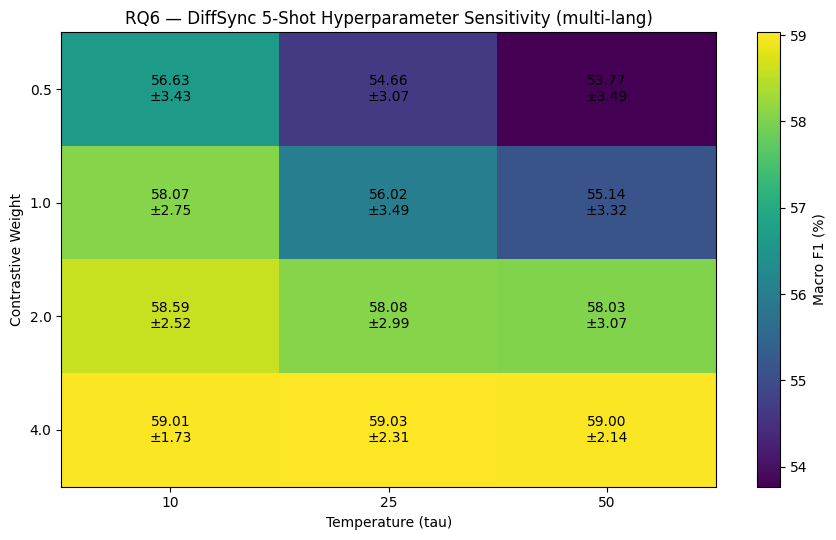

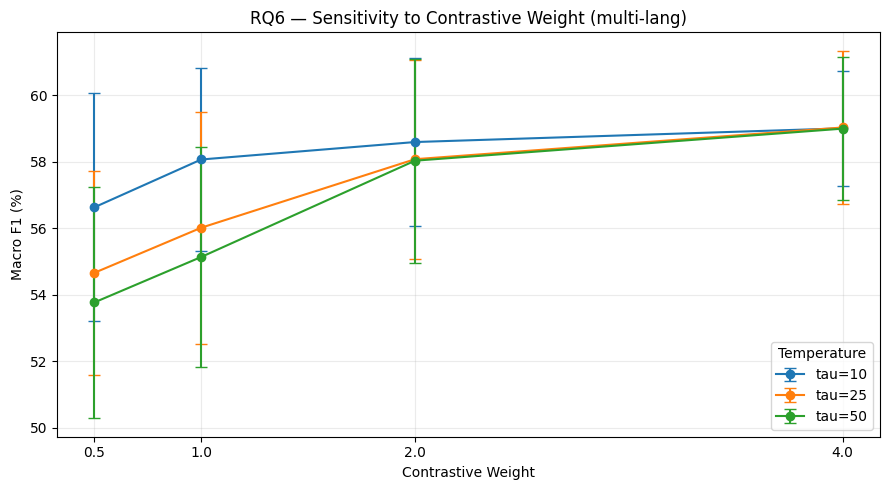


RQ6 EXPERIMENT COMPLETED
Dataset: multi-lang
Setting: 5-Shot
Configurations: 12
Seed-level results: 60
Baseline status: WARNING
Elapsed seconds: 268.2

Original parameters restored:
  tau = 25.0
  fs_con_weight = 2.0

Saved outputs:
  seed_results: /kaggle/working/rq6_multi-lang_seed_results.csv
  summary: /kaggle/working/rq6_multi-lang_sensitivity_summary.csv
  table: /kaggle/working/rq6_multi-lang_sensitivity_table.csv
  metadata: /kaggle/working/rq6_multi-lang_metadata.csv
  heatmap: /kaggle/working/rq6_multi-lang_sensitivity_heatmap.png
  trend plot: /kaggle/working/rq6_multi-lang_sensitivity_trends.png

No model architecture changes.
No selection of hyperparameters using test F1.
All 12 configurations reported.


In [2]:
# ================================================================
# RQ6 — HYPERPARAMETER SENSITIVITY ANALYSIS
# DiffSync | Multi-lang | 5-Shot | 5 Seeds
#
# Grid:
#   Contrastive weight: [0.5, 1.0, 2.0, 4.0]
#   Temperature:        [10, 25, 50]
#
# Scientific guarantees:
# - Original model architecture unchanged
# - Original support sampling unchanged
# - Same five seeds across all configurations
# - Contrastive encoder trained only once per seed
# - Frozen embeddings reused
# - Self-training supported if enabled
# - All results reported, not best-only
# - Original CFG and functions restored
# ================================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score

# ================================================================
# 0. CONFIGURATION
# ================================================================

RQ6_DATASET = "multi-lang"
RQ6_K = 5

RQ6_WEIGHTS = [0.5, 1.0, 2.0, 4.0]
RQ6_TAUS = [10, 25, 50]

RQ6_SEEDS = list(CFG["fs_seeds"])

RQ6_BASELINE_WEIGHT = 2.0
RQ6_BASELINE_TAU = 25

# Previously reported 5-shot mean F1 on Multi-lang.
# Set to 0.0 if unknown; reference only, never used for optimization.
RQ6_REFERENCE_F1 = 0.0
RQ6_REFERENCE_TOLERANCE = 0.50

RQ6_OUT = CFG.get("out_dir") or (
    "/kaggle/working"
    if os.path.isdir("/kaggle/working")
    else "."
)

os.makedirs(RQ6_OUT, exist_ok=True)

assert CFG["dataset"].lower() == RQ6_DATASET
assert CFG["fs_contrastive"] is True
assert RQ6_K in CFG["shots"]
assert len(RQ6_SEEDS) == 5
assert len(set(RQ6_SEEDS)) == 5

# Preserve original references and configuration.
RQ6_ORIGINAL_TAU = CFG["tau"]
RQ6_ORIGINAL_WEIGHT = CFG["fs_con_weight"]
RQ6_ORIGINAL_HEAD = head_probs

RQ6_START = time.time()

print("=" * 85)
print("RQ6 — HYPERPARAMETER SENSITIVITY")
print("=" * 85)

print("Dataset:", RQ6_DATASET)
print("Shots:", RQ6_K)
print("Seeds:", RQ6_SEEDS)
print("Weights:", RQ6_WEIGHTS)
print("Temperatures:", RQ6_TAUS)
print("Original tau:", RQ6_ORIGINAL_TAU)
print("Original weight:", RQ6_ORIGINAL_WEIGHT)

# ================================================================
# 1. DATASET AND FROZEN EMBEDDINGS
# ================================================================

set_seed(42)

RQ6_D = add_text_fields(
    load_dataset_by_name_strict(RQ6_DATASET)
)

RQ6_SP = RQ6_D["split"].values

RQ6_TRAIN_IDX = np.where(
    RQ6_SP == "train"
)[0]

RQ6_TEST_IDX = np.where(
    RQ6_SP == "test"
)[0]

RQ6_Y_TEST = RQ6_D["y"].values[
    RQ6_TEST_IDX
]

RQ6_LEXP = lex_probs_from_counts(
    np.stack([
        lex_counts(m)
        for m in RQ6_D["message"]
    ]),
    CFG["lex_beta"]
)

print("\n[RQ6] Computing frozen embeddings once...")

RQ6_EMB = compute_frozen_views(RQ6_D)

RQ6_TRAIN_UNIQUE = (
    RQ6_D.iloc[RQ6_TRAIN_IDX]
    .drop_duplicates(subset=["message"])
)

assert len(RQ6_TEST_IDX) > 0
assert len(RQ6_TRAIN_IDX) > 0

print("[RQ6] Dataset samples:", len(RQ6_D))
print("[RQ6] Test samples:", len(RQ6_TEST_IDX))
print("[RQ6] Frozen views:", list(RQ6_EMB))

# ================================================================
# 2. SAME SUPPORT SELECTION AS ORIGINAL MODEL
# ================================================================

def rq6_support(k, seed):

    chunks = [
        group.sample(
            n=min(k, len(group)),
            random_state=seed
        )
        for _, group in
        RQ6_TRAIN_UNIQUE.groupby("label")
    ]

    support = pd.concat(chunks)

    sup_idx = support.index.values
    sup_y = support["y"].values.astype(int)

    assert len(sup_idx) == NC * k
    assert len(np.unique(sup_idx)) == len(sup_idx)

    return sup_idx, sup_y


# ================================================================
# 3. COMPUTE FROZEN VIEW PROBABILITIES FOR EACH TAU
# ================================================================

def rq6_frozen_for_tau(
    support_idx,
    support_y,
    tau
):
    """
    Calls original frozen_view_probs(), preserving
    prototype, anchors and LR-head behavior.

    Only the temperature is temporarily varied.
    """

    old_tau = CFG["tau"]

    try:
        CFG["tau"] = float(tau)

        probs = frozen_view_probs(
            RQ6_EMB,
            RQ6_TRAIN_IDX,
            support_idx,
            support_y,
            RQ6_TEST_IDX,
            RQ6_K
        )

        return {
            name: value.copy()
            for name, value in probs.items()
        }

    finally:
        CFG["tau"] = old_tau


# ================================================================
# 4. OPTIONAL SELF-TRAINING
# ================================================================

def rq6_selftrain_for_tau(
    support_idx,
    support_y,
    tau
):
    """
    Reproduces original few-shot self-training.

    Pseudo labels must be recomputed for each tau,
    because tau can change their confidence/ranking.
    """

    if not CFG["self_train"]:
        return rq6_frozen_for_tau(
            support_idx, support_y, tau
        )

    pool_idx = np.setdiff1d(
        RQ6_TRAIN_IDX,
        support_idx
    )

    old_tau = CFG["tau"]

    try:
        CFG["tau"] = float(tau)

        pool_probs = frozen_view_probs(
            RQ6_EMB,
            RQ6_TRAIN_IDX,
            support_idx,
            support_y,
            pool_idx,
            RQ6_K
        )

        pp = combine(
            pool_probs,
            RQ6_LEXP[pool_idx],
            RQ6_K
        )

        conf = pp.max(axis=1)
        pred = pp.argmax(axis=1)

        picks = []

        for c in range(NC):

            ids = np.where(pred == c)[0]

            picks.extend(
                ids[np.argsort(-conf[ids])][
                    :CFG["self_train_per_class"]
                ].tolist()
            )

        picks = np.array(picks, dtype=int)

        extra = None

        if len(picks):

            extra = (
                pool_idx[picks],
                pred[picks],
                np.full(
                    len(picks),
                    CFG["self_train_w"]
                )
            )

        result = frozen_view_probs(
            RQ6_EMB,
            RQ6_TRAIN_IDX,
            support_idx,
            support_y,
            RQ6_TEST_IDX,
            RQ6_K,
            extra=extra
        )

        return {
            name: value.copy()
            for name, value in result.items()
        }

    finally:
        CFG["tau"] = old_tau


# ================================================================
# 5. CONTRASTIVE ENCODER — TRAIN ONCE PER SEED
# ================================================================

def rq6_contrastive_all_taus(
    support_idx,
    support_y,
    seed
):
    """
    Execute original contrastive_view_probs only once.

    The original head_probs() is temporarily wrapped
    so the SAME trained contrastive embeddings are
    evaluated at all required temperatures.

    No new architecture or training objective.
    """

    captured = {}

    def capture_head(
        Xs, ys, ws, Xq, k, mu
    ):

        old_tau = CFG["tau"]

        try:
            for tau in RQ6_TAUS:

                CFG["tau"] = float(tau)

                captured[tau] = (
                    RQ6_ORIGINAL_HEAD(
                        Xs, ys, ws, Xq, k, mu
                    ).copy()
                )

        finally:
            CFG["tau"] = old_tau

        return captured[RQ6_BASELINE_TAU]

    old_head = globals()["head_probs"]

    try:

        globals()["head_probs"] = capture_head

        # The only expensive contrastive training
        # call for this seed.
        _ = contrastive_view_probs(
            RQ6_D,
            RQ6_EMB,
            support_idx,
            support_y,
            RQ6_TRAIN_IDX,
            RQ6_TEST_IDX,
            RQ6_K,
            seed
        )

    finally:
        globals()["head_probs"] = old_head

    if set(captured) != set(RQ6_TAUS):
        raise RuntimeError(
            "Contrastive capture incomplete. "
            f"Expected {RQ6_TAUS}, got {list(captured)}"
        )

    for tau, probs in captured.items():

        assert probs.shape == (
            len(RQ6_TEST_IDX), NC
        )

        assert np.all(np.isfinite(probs))

    return captured


# ================================================================
# 6. CACHE ALL SEED × TAU PROBABILITIES
# ================================================================

RQ6_CACHE = {}

try:

    for seed in RQ6_SEEDS:

        print("\n" + "=" * 80)
        print(f"[RQ6] PREPARING SEED {seed}")
        print("=" * 80)

        sup_idx, sup_y = rq6_support(
            RQ6_K, seed
        )

        # Frozen heads and possible pseudo-labeling
        # are recomputed per temperature.
        frozen_by_tau = {}

        for tau in RQ6_TAUS:

            frozen_by_tau[tau] = (
                rq6_selftrain_for_tau(
                    sup_idx,
                    sup_y,
                    tau
                )
            )

            print(
                f"  Frozen views ready: tau={tau}"
            )

        print(
            "  Training contrastive encoder "
            "(once for this seed)..."
        )

        contrastive_by_tau = (
            rq6_contrastive_all_taus(
                sup_idx,
                sup_y,
                seed
            )
        )

        for tau in RQ6_TAUS:

            probs = {
                name: value.copy()
                for name, value
                in frozen_by_tau[tau].items()
            }

            probs["contrastive"] = (
                contrastive_by_tau[tau].copy()
            )

            RQ6_CACHE[(seed, tau)] = probs

        print(f"  Seed {seed}: CACHE READY")

finally:

    # No permanent modifications, even on error.
    CFG["tau"] = RQ6_ORIGINAL_TAU

    CFG["fs_con_weight"] = (
        RQ6_ORIGINAL_WEIGHT
    )

    globals()["head_probs"] = (
        RQ6_ORIGINAL_HEAD
    )


# ================================================================
# 7. EVALUATE THE 12-PARAMETER GRID
# ================================================================

RQ6_RECORDS = []

try:

    for weight in RQ6_WEIGHTS:

        for tau in RQ6_TAUS:

            CFG["tau"] = float(tau)

            CFG["fs_con_weight"] = (
                float(weight)
            )

            scores = []

            for seed in RQ6_SEEDS:

                probs_by_view = (
                    RQ6_CACHE[(seed, tau)]
                )

                # Same original combine() and
                # contrastive weighting semantics.
                final_probs = combine(
                    probs_by_view,
                    RQ6_LEXP[RQ6_TEST_IDX],
                    RQ6_K,
                    weights={
                        "contrastive": weight
                    }
                )

                pred = final_probs.argmax(axis=1)

                score = 100 * f1_score(
                    RQ6_Y_TEST,
                    pred,
                    average="macro",
                    zero_division=0
                )

                scores.append(float(score))

                RQ6_RECORDS.append({
                    "Dataset": RQ6_DATASET,
                    "Shots": RQ6_K,
                    "Contrastive_Weight": weight,
                    "Temperature": tau,
                    "Seed": seed,
                    "Macro_F1": float(score)
                })

            print(
                f"weight={weight:<4} "
                f"tau={tau:<3} | "
                f"Macro F1 = "
                f"{np.mean(scores):.3f} "
                f"± {np.std(scores, ddof=0):.3f}"
            )

finally:

    CFG["tau"] = RQ6_ORIGINAL_TAU

    CFG["fs_con_weight"] = (
        RQ6_ORIGINAL_WEIGHT
    )

    globals()["head_probs"] = (
        RQ6_ORIGINAL_HEAD
    )


# ================================================================
# 8. AGGREGATE MEAN AND SD
# ================================================================

RQ6_SEED_DF = pd.DataFrame(RQ6_RECORDS)

RQ6_SUMMARY = (
    RQ6_SEED_DF
    .groupby(
        ["Contrastive_Weight", "Temperature"],
        as_index=False
    )
    .agg(
        Mean_F1=("Macro_F1", "mean"),
        SD_F1=(
            "Macro_F1",
            lambda x: float(
                np.std(x.values, ddof=0)
            )
        ),
        Min_F1=("Macro_F1", "min"),
        Max_F1=("Macro_F1", "max"),
        N_Seeds=("Macro_F1", "count")
    )
)

assert len(RQ6_SUMMARY) == 12

assert (
    RQ6_SUMMARY["N_Seeds"] == 5
).all()

# ================================================================
# 9. BASELINE CONSISTENCY CHECK
# ================================================================

baseline = RQ6_SUMMARY[
    (
        RQ6_SUMMARY["Contrastive_Weight"]
        == RQ6_BASELINE_WEIGHT
    )
    &
    (
        RQ6_SUMMARY["Temperature"]
        == RQ6_BASELINE_TAU
    )
]

assert len(baseline) == 1

RQ6_BASELINE_F1 = float(
    baseline.iloc[0]["Mean_F1"]
)

RQ6_BASELINE_SD = float(
    baseline.iloc[0]["SD_F1"]
)

RQ6_BASELINE_DIFF = (
    RQ6_BASELINE_F1 - RQ6_REFERENCE_F1
)

RQ6_BASELINE_STATUS = (
    "PASS"
    if abs(RQ6_BASELINE_DIFF)
    <= RQ6_REFERENCE_TOLERANCE
    else "WARNING"
)

print("\n" + "=" * 85)
print("RQ6 — BASELINE VERIFICATION")
print("=" * 85)

print(
    "Reference:",
    f"{RQ6_REFERENCE_F1:.3f}%"
)

print(
    "Reproduced:",
    f"{RQ6_BASELINE_F1:.3f}%"
)

print(
    "SD:",
    f"{RQ6_BASELINE_SD:.3f}"
)

print(
    "Difference:",
    f"{RQ6_BASELINE_DIFF:+.3f} pp"
)

print("Status:", RQ6_BASELINE_STATUS)


# ================================================================
# 10. FINAL SENSITIVITY TABLE
# ================================================================

RQ6_DISPLAY = RQ6_SUMMARY.copy()

RQ6_DISPLAY["F1_Mean_SD"] = (
    RQ6_DISPLAY.apply(
        lambda r:
        f"{r['Mean_F1']:.2f} ± {r['SD_F1']:.2f}",
        axis=1
    )
)

RQ6_TABLE = (
    RQ6_DISPLAY.pivot(
        index="Contrastive_Weight",
        columns="Temperature",
        values="F1_Mean_SD"
    )
    .reindex(
        index=RQ6_WEIGHTS,
        columns=RQ6_TAUS
    )
)

print("\n" + "=" * 85)
print("RQ6 — HYPERPARAMETER SENSITIVITY TABLE")
print("=" * 85)

print(RQ6_TABLE.to_string())


# ================================================================
# 11. HEATMAP
# ================================================================

heatmap_df = (
    RQ6_SUMMARY.pivot(
        index="Contrastive_Weight",
        columns="Temperature",
        values="Mean_F1"
    )
    .reindex(
        index=RQ6_WEIGHTS,
        columns=RQ6_TAUS
    )
)

values = heatmap_df.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(9, 5.5))

im = ax.imshow(
    values,
    aspect="auto"
)

ax.set_xticks(range(len(RQ6_TAUS)))
ax.set_yticks(range(len(RQ6_WEIGHTS)))

ax.set_xticklabels(RQ6_TAUS)
ax.set_yticklabels(RQ6_WEIGHTS)

ax.set_xlabel("Temperature (tau)")
ax.set_ylabel("Contrastive Weight")

ax.set_title(
    f"RQ6 — DiffSync 5-Shot Hyperparameter Sensitivity ({RQ6_DATASET})"
)

for i in range(len(RQ6_WEIGHTS)):

    for j in range(len(RQ6_TAUS)):

        mean = values[i, j]

        sd = RQ6_SUMMARY.loc[
            (
                RQ6_SUMMARY["Contrastive_Weight"]
                == RQ6_WEIGHTS[i]
            )
            &
            (
                RQ6_SUMMARY["Temperature"]
                == RQ6_TAUS[j]
            ),
            "SD_F1"
        ].iloc[0]

        ax.text(
            j, i,
            f"{mean:.2f}\n±{sd:.2f}",
            ha="center",
            va="center",
            fontsize=10
        )

fig.colorbar(
    im,
    ax=ax,
    label="Macro F1 (%)"
)

plt.tight_layout()

RQ6_HEATMAP_PATH = os.path.join(
    RQ6_OUT,
    f"rq6_{RQ6_DATASET}_sensitivity_heatmap.png"
)

plt.savefig(
    RQ6_HEATMAP_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 12. ADDITIONAL PLOT — PARAMETER TRENDS
# ================================================================

fig, ax = plt.subplots(figsize=(9, 5))

for tau in RQ6_TAUS:

    df_tau = RQ6_SUMMARY[
        RQ6_SUMMARY["Temperature"] == tau
    ].sort_values("Contrastive_Weight")

    ax.errorbar(
        df_tau["Contrastive_Weight"],
        df_tau["Mean_F1"],
        yerr=df_tau["SD_F1"],
        marker="o",
        capsize=4,
        label=f"tau={tau}"
    )

ax.set_xlabel("Contrastive Weight")
ax.set_ylabel("Macro F1 (%)")

ax.set_title(
    f"RQ6 — Sensitivity to Contrastive Weight ({RQ6_DATASET})"
)

ax.set_xticks(RQ6_WEIGHTS)

ax.legend(title="Temperature")
ax.grid(alpha=0.25)

plt.tight_layout()

RQ6_TREND_PATH = os.path.join(
    RQ6_OUT,
    f"rq6_{RQ6_DATASET}_sensitivity_trends.png"
)

plt.savefig(
    RQ6_TREND_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 13. SAVE TABLES AND METADATA
# ================================================================

RQ6_PATHS = {
    "seed_results": os.path.join(
        RQ6_OUT,
        f"rq6_{RQ6_DATASET}_seed_results.csv"
    ),
    "summary": os.path.join(
        RQ6_OUT,
        f"rq6_{RQ6_DATASET}_sensitivity_summary.csv"
    ),
    "table": os.path.join(
        RQ6_OUT,
        f"rq6_{RQ6_DATASET}_sensitivity_table.csv"
    ),
    "metadata": os.path.join(
        RQ6_OUT,
        f"rq6_{RQ6_DATASET}_metadata.csv"
    )
}

RQ6_SEED_DF.to_csv(
    RQ6_PATHS["seed_results"],
    index=False
)

RQ6_SUMMARY.to_csv(
    RQ6_PATHS["summary"],
    index=False
)

RQ6_TABLE.to_csv(
    RQ6_PATHS["table"]
)

elapsed = time.time() - RQ6_START

RQ6_METADATA = pd.DataFrame([{
    "Dataset": RQ6_DATASET,
    "Shots": RQ6_K,
    "N_Seeds": len(RQ6_SEEDS),
    "N_Configurations": len(RQ6_SUMMARY),
    "Original_Tau": RQ6_ORIGINAL_TAU,
    "Original_Contrastive_Weight":
        RQ6_ORIGINAL_WEIGHT,
    "Baseline_F1": RQ6_BASELINE_F1,
    "Baseline_SD": RQ6_BASELINE_SD,
    "Reference_F1": RQ6_REFERENCE_F1,
    "Baseline_Difference_pp": RQ6_BASELINE_DIFF,
    "Baseline_Status": RQ6_BASELINE_STATUS,
    "Self_Training": CFG["self_train"],
    "Elapsed_Seconds": elapsed
}])

RQ6_METADATA.to_csv(
    RQ6_PATHS["metadata"],
    index=False
)


# ================================================================
# 14. FINAL INTEGRITY CHECK
# ================================================================

assert CFG["tau"] == RQ6_ORIGINAL_TAU

assert (
    CFG["fs_con_weight"]
    == RQ6_ORIGINAL_WEIGHT
)

assert (
    globals()["head_probs"]
    is RQ6_ORIGINAL_HEAD
)

print("\n" + "=" * 90)
print("RQ6 EXPERIMENT COMPLETED")
print("=" * 90)

print("Dataset:", RQ6_DATASET)
print("Setting: 5-Shot")
print("Configurations:", len(RQ6_SUMMARY))
print("Seed-level results:", len(RQ6_SEED_DF))
print("Baseline status:", RQ6_BASELINE_STATUS)
print("Elapsed seconds:", round(elapsed, 1))

print("\nOriginal parameters restored:")
print("  tau =", CFG["tau"])
print("  fs_con_weight =", CFG["fs_con_weight"])

print("\nSaved outputs:")

for label, path in RQ6_PATHS.items():
    print(f"  {label}: {path}")

print("  heatmap:", RQ6_HEATMAP_PATH)
print("  trend plot:", RQ6_TREND_PATH)

print("\nNo model architecture changes.")
print("No selection of hyperparameters using test F1.")
print("All 12 configurations reported.")